# Exercise 6
**Veikka Immonen**

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from collections.abc import Iterable
from tqdm import tqdm

import torch
from torch.nn import Module, Sequential, Linear, Tanh, ReLU, MSELoss, Parameter
from torch.optim import Adam

import scienceplots
plt.style.use(['science'])

## Matérn sampler via SPDE approximation

## Space-varying kernel width optimization

### Prerequisites

In [ ]:
n_full = 400
n_data = 50
m = 20
sigma_noise = 0.1

t_full = torch.linspace(0, 1, n_full + 1)[:-1]
t_data = torch.linspace(0, 1, n_data + 1)[:-1]

data_dict = torch.load("data.pt")
theta_true = data_dict["theta"].float()
X = data_dict["X"].float()
Y = data_dict["Y"].float()



### Neural network

The neural network $\theta(t) \approx \tilde{\theta}(t) = \Psi(\tilde{t}; \{\bm{W}_i,\bm{b}_i\}_{i=1}^L)$ computes for each layer $i$:
* $\bm{z}_i = \bm{W}_i \bm{x}_{i-1} + \bm{b}_i$
* $\bm{x}_i = \begin{cases}\exp(\bm{z_i}) & i = L \\\tanh(\bm{z_i}) & \text{otherwise,} \end{cases}$

The net is initialized with one hidden layer of size 64.
$t\rightarrow\tilde{t}$ is a linear mapping $[0, 1] \rightarrow [-1, 1]$.
 

In [76]:
class Model(Module):
    def __init__(self):
        super().__init__()
        self.layers = Sequential(
            Linear(1, 64),
            Tanh(),
            Linear(64, 1, bias=False),
        )
        self.bias = Parameter(torch.FloatTensor([-3]))
    def forward(self, x):
        return (self.layers(x) + self.bias).exp()


def boxcar(t1, t2, theta):
    n, m = map(len, (t1, t2))
    step = n / m
    dt = (t1[1] - t1[0]).item()
    if isinstance(theta, Iterable):
        assert len(theta) == len(t1)
        c = torch.where(theta.abs() < dt, 1.0, dt / (2 * theta))
    else:
        c = 1.0 if abs(theta) < dt else dt / (2 * theta)
        c = torch.full_like(t1, c)
        theta = torch.full_like(t1, theta)
    # triplets = []
    k = torch.zeros((m, n), dtype=theta.dtype)
    for i in range(m):
        loc = int(round(i * step))
        for j in range(n):
            d = abs(t2[i] - t1[j])
            d_periodic = min(d, 1.0 - d)
            if d_periodic <= theta[loc]:
                k[i, j] = c[loc]
                # triplets.append((i, j, c[loc]))
    # rows, cols, vals = map(list, zip(*triplets))
    # k = torch.sparse_coo_tensor([rows, cols], vals, size=(m, n))
    k /= k.sum(dim=1, keepdim=True)
    return k

### Draw random samples

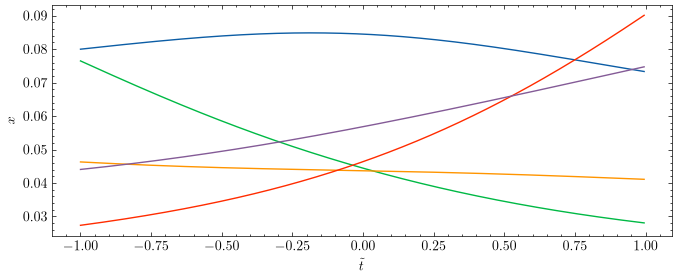

In [131]:
_, ax = plt.subplots(figsize=(8, 3))
ax.set_xlabel(r"$\tilde{t}$")
ax.set_ylabel(r"$x$")

input = (2 * t_full - 1).unsqueeze(1).float()

for _ in range(5):
    net = Model()
    with torch.inference_mode():
        sample = net(input)
        plt.plot(input, sample)


plt.savefig("samples_1.pdf")
plt.show()

### Estimate with Adam

* learning rate: $\eta = 0.01$
* weight decay: $\lambda = 0.001$ to all parameters except from last bias parameter.
* last bias parameter starting value: -2
* 100 epochs

In [77]:
input = (2 * t_full - 1).unsqueeze(1).float()
net = Model()

criterion = MSELoss()
optimizer = Adam(
    [
        {'params': net.layers.parameters(), 'weight_decay': 1e-3},
        {'params': [net.bias],              'weight_decay': 0.0},
    ],
    lr=0.01
)

epochs = 100
losses = []
net.train()
for _ in tqdm(range(epochs)):
    optimizer.zero_grad()
    theta = net(input).ravel()
    K = boxcar(t_full, t_data, theta)
    pred = X @ K.T
    loss = criterion(pred, Y)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())


100%|██████████| 100/100 [00:09<00:00, 10.78it/s]


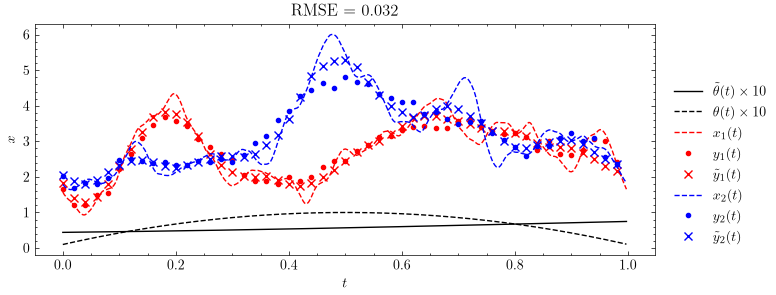

In [132]:
net.eval()
with torch.inference_mode():
    theta = net(input).ravel()
    pred = X @ boxcar(t_full, t_data, theta).T

_, ax = plt.subplots(figsize=(8, 3))
ax.set_xlabel("$t$")
ax.set_ylabel("$x$")

ax.plot(t_full, theta*10, 'k', label=r"$\tilde{\theta}(t) \times 10$")
ax.plot(t_full, theta_true*10, 'k--', label=r"$\theta(t) \times 10$")
ax.plot(t_full, X[0], 'r--', label=r"$x_1(t)$")
ax.plot(t_data, Y[0], 'r.', label=r"$y_1(t)$")
ax.plot(t_data, pred[0], 'rx', label=r"$\tilde{y}_1(t)$")
ax.plot(t_full, X[1], 'b--', label=r"$x_2(t)$")
ax.plot(t_data, Y[1], 'b.', label=r"$y_2(t)$")
ax.plot(t_data, pred[1], 'bx', label=r"$\tilde{y}_2(t)$")
ax.legend(bbox_to_anchor=(1.2, 0.8))

RMSE = torch.norm(theta - theta_true) / len(theta)**.5
ax.set_title(f"{RMSE = :.3f}")

plt.savefig("adam_1.pdf")
plt.show()